In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/05_smart_agriculture_crop_digital_twin.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (500, 15)


,Field_ID,Crop_Type,Soil_Moisture,Soil_pH,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,Rainfall,Irrigation_Hours,Pest_Index,Previous_Yield,Crop_Health,Predicted_Yield
0,F001,Maize,52.3,7.11,58.4,37.4,73.7,20.2,55.3,4.4,1.6,37.5,4.07,Poor,3.73
1,F002,Cotton,56.4,6.56,69.8,39.9,52.7,27.2,60.6,46.5,3.6,12.2,4.97,Moderate,5.35
2,F003,Maize,28.9,6.18,44.0,40.5,46.6,35.6,67.6,106.0,0.2,21.9,5.23,Poor,4.63
3,F004,Rice,37.7,6.66,64.3,45.0,72.8,27.9,57.9,119.8,5.8,20.7,5.80,Moderate,5.92
4,F005,Cotton,59.1,6.60,56.4,20.2,29.0,29.0,54.7,0.0,0.9,29.5,3.44,Poor,3.25


In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

if "Field_ID" in df.columns:
    print("Duplicate Field_ID values:", df["Field_ID"].duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.strip()

# Remove duplicate rows
df = df.drop_duplicates()

# Keep only one row for each Field_ID
if "Field_ID" in df.columns:
    df = df.drop_duplicates(subset=["Field_ID"])

# Remove rows without the target value
df = df.dropna(subset=["Crop_Health"])

print("\nShape after cleaning:", df.shape)
print("\nCrop Health distribution:")
print(df["Crop_Health"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Field_ID          500 non-null    object 
 1   Crop_Type         500 non-null    object 
 2   Soil_Moisture     500 non-null    float64
 3   Soil_pH           500 non-null    float64
 4   Nitrogen          500 non-null    float64
 5   Phosphorus        500 non-null    float64
 6   Potassium         500 non-null    float64
 7   Temperature       500 non-null    float64
 8   Humidity          500 non-null    float64
 9   Rainfall          500 non-null    float64
 10  Irrigation_Hours  500 non-null    float64
 11  Pest_Index        500 non-null    float64
 12  Previous_Yield    500 non-null    float64
 13  Crop_Health       500 non-null    object 
 14  Predicted_Yield   500 non-null    float64
dtypes: float64(12), object(3)
memory usage: 58.7+ KB

Missing values:
Fiel

,Field_ID,Crop_Type,Soil_Moisture,Soil_pH,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,Rainfall,Irrigation_Hours,Pest_Index,Previous_Yield,Crop_Health,Predicted_Yield
count,500,500,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500,500.000000
unique,500,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,F500,Groundnut,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Poor,NaN
freq,1,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,320,NaN
mean,NaN,NaN,57.515200,6.701760,55.932200,37.357200,48.38140,28.192000,65.513400,84.616200,3.426400,25.404800,5.178100,NaN,5.139280
std,NaN,NaN,17.198264,0.677701,19.969211,14.252965,17.59531,4.203193,11.869543,51.839771,1.882176,16.449808,1.111428,NaN,0.971399
min,NaN,NaN,15.000000,5.000000,10.000000,5.000000,10.00000,18.000000,30.700000,0.000000,0.000000,0.000000,1.930000,NaN,2.580000
25%,NaN,NaN,45.125000,6.227500,41.950000,27.675000,35.67500,25.300000,57.550000,44.075000,2.000000,13.200000,4.387500,NaN,4.410000
50%,NaN,NaN,56.850000,6.690000,55.300000,38.200000,48.00000,28.300000,66.350000,81.700000,3.300000,24.000000,5.190000,NaN,5.125000
75%,NaN,NaN,69.275000,7.180000,70.450000,46.450000,59.52500,31.125000,73.600000,121.600000,4.700000,36.800000,5.980000,NaN,5.822500



Shape after cleaning: (500, 15)

Crop Health distribution:
Crop_Health
Poor        320
Moderate    163
Healthy      17
Name: count, dtype: int64


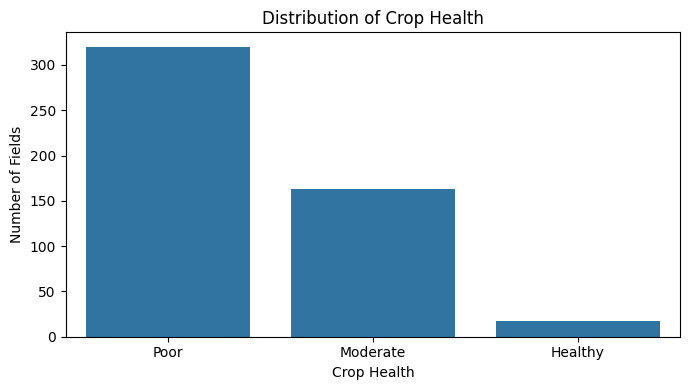

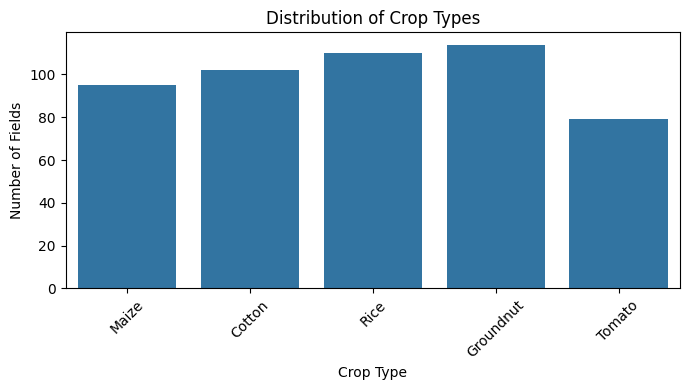

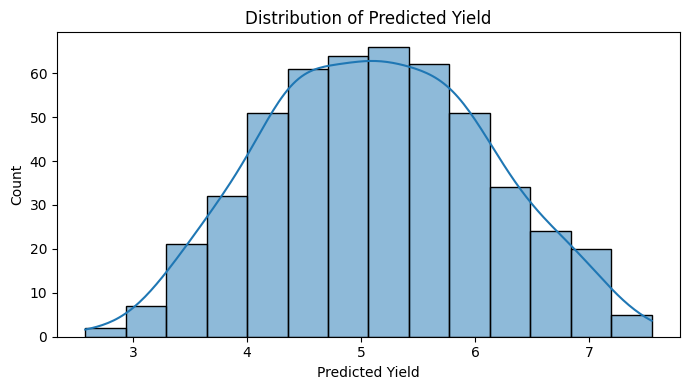

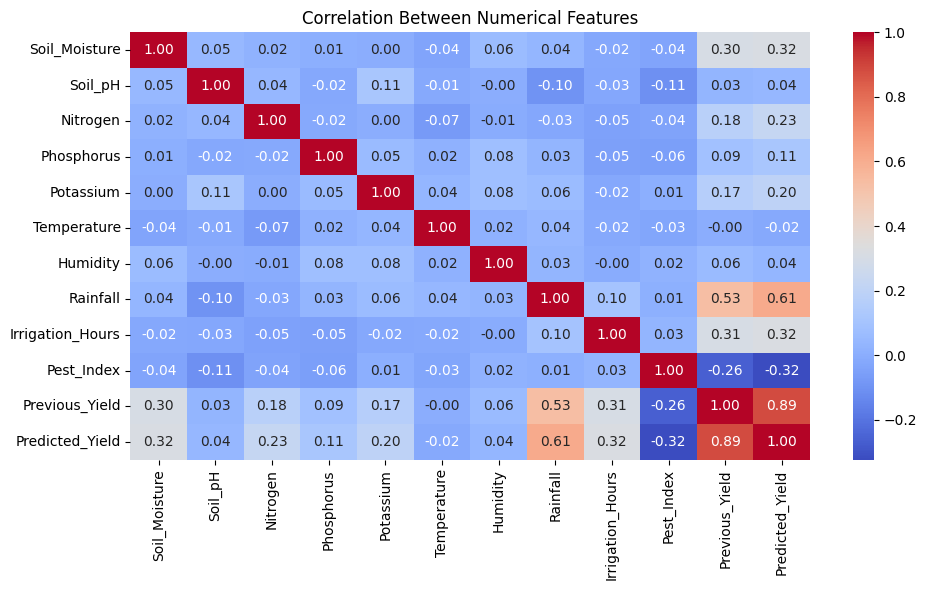

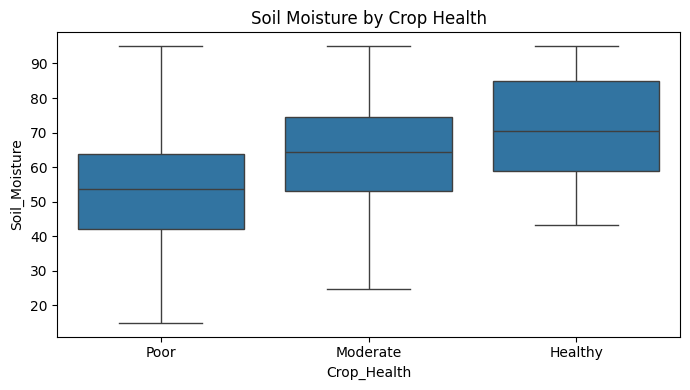

In [ ]:
#EDA
# 1. Distribution of crop health
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Crop_Health")
plt.title("Distribution of Crop Health")
plt.xlabel("Crop Health")
plt.ylabel("Number of Fields")
plt.tight_layout()
plt.show()

# 2. Crop type distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Crop_Type")
plt.title("Distribution of Crop Types")
plt.xlabel("Crop Type")
plt.ylabel("Number of Fields")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Predicted yield distribution
if "Predicted_Yield" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df["Predicted_Yield"].dropna(), kde=True)
    plt.title("Distribution of Predicted Yield")
    plt.xlabel("Predicted Yield")
    plt.tight_layout()
    plt.show()

# 4. Correlation heatmap for numerical columns
numeric_df = df.select_dtypes(include=["number"])

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

# 5. Soil moisture versus crop health
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Crop_Health", y="Soil_Moisture")
plt.title("Soil Moisture by Crop Health")
plt.tight_layout()
plt.show()

In [ ]:
TARGET = "Crop_Health"

# Do not use identifiers or Predicted_Yield as input features
drop_columns = ["Crop_Health", "Field_ID", "Predicted_Yield"]

X = df.drop(columns=drop_columns, errors="ignore").copy()
y = df[TARGET].copy()

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

# Split before fitting imputers, encoders, or scalers
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a fresh preprocessing pipeline for each model
def create_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, num_cols),
        ("categorical", categorical_pipeline, cat_cols)
    ])

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nPreprocessing setup completed!")

Numerical columns: ['Soil_Moisture', 'Soil_pH', 'Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'Rainfall', 'Irrigation_Hours', 'Pest_Index', 'Previous_Yield']
Categorical columns: ['Crop_Type']

Training samples: 400
Testing samples: 100

Preprocessing setup completed!


In [ ]:
#Logistic regression
lr_model = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, lr_pred))

print("Macro Precision:",
      precision_score(y_test, lr_pred, average="macro", zero_division=0))

print("Macro Recall:",
      recall_score(y_test, lr_pred, average="macro", zero_division=0))

print("Macro F1 Score:",
      f1_score(y_test, lr_pred, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.63
Macro Precision: 0.45273919753086417
Macro Recall: 0.49763257575757575
Macro F1 Score: 0.4552083333333334

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.11      0.33      0.17         3
    Moderate       0.48      0.39      0.43        33
        Poor       0.77      0.77      0.77        64

    accuracy                           0.63       100
   macro avg       0.45      0.50      0.46       100
weighted avg       0.65      0.63      0.64       100

Confusion Matrix:
[[ 1  2  0]
 [ 5 13 15]
 [ 3 12 49]]


In [ ]:
#Decision tree
dt_model = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("DECISION TREE RESULTS")

print("Accuracy:",
      accuracy_score(y_test, dt_pred))

print("Macro Precision:",
      precision_score(y_test, dt_pred, average="macro", zero_division=0))

print("Macro Recall:",
      recall_score(y_test, dt_pred, average="macro", zero_division=0))

print("Macro F1 Score:",
      f1_score(y_test, dt_pred, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

DECISION TREE RESULTS
Accuracy: 0.65
Macro Precision: 0.47323717948717947
Macro Recall: 0.5129419191919192
Macro F1 Score: 0.46989080834419816

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.10      0.33      0.15         3
    Moderate       0.54      0.42      0.47        33
        Poor       0.78      0.78      0.78        64

    accuracy                           0.65       100
   macro avg       0.47      0.51      0.47       100
weighted avg       0.68      0.65      0.66       100

Confusion Matrix:
[[ 1  2  0]
 [ 5 14 14]
 [ 4 10 50]]


In [ ]:
#random forest
rf_model = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("RANDOM FOREST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Macro Precision:",
      precision_score(y_test, rf_pred, average="macro", zero_division=0))

print("Macro Recall:",
      recall_score(y_test, rf_pred, average="macro", zero_division=0))

print("Macro F1 Score:",
      f1_score(y_test, rf_pred, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST RESULTS
Accuracy: 0.69
Macro Precision: 0.42540792540792544
Macro Recall: 0.41808712121212127
Macro F1 Score: 0.4130601792573623

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00         3
    Moderate       0.55      0.36      0.44        33
        Poor       0.73      0.89      0.80        64

    accuracy                           0.69       100
   macro avg       0.43      0.42      0.41       100
weighted avg       0.65      0.69      0.66       100

Confusion Matrix:
[[ 0  3  0]
 [ 0 12 21]
 [ 0  7 57]]


In [14]:
#SVM
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create SVM model
svm_model = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced"
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

# Predict crop health
svm_pred = svm_model.predict(X_test)

# Evaluate the model
print("SUPPORT VECTOR MACHINE (SVM) RESULTS")

print("Accuracy:",
      accuracy_score(y_test, svm_pred))

print("Macro Precision:",
      precision_score(
          y_test, svm_pred,
          average="macro",
          zero_division=0
      ))

print("Macro Recall:",
      recall_score(
          y_test, svm_pred,
          average="macro",
          zero_division=0
      ))

print("Macro F1 Score:",
      f1_score(
          y_test, svm_pred,
          average="macro",
          zero_division=0
      ))

print("\nClassification Report:")
print(classification_report(
    y_test, svm_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

SUPPORT VECTOR MACHINE (SVM) RESULTS
Accuracy: 0.65
Macro Precision: 0.4959057071960298
Macro Recall: 0.5178345959595959
Macro F1 Score: 0.5047180693983019

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.25      0.33      0.29         3
    Moderate       0.48      0.45      0.47        33
        Poor       0.75      0.77      0.76        64

    accuracy                           0.65       100
   macro avg       0.50      0.52      0.50       100
weighted avg       0.65      0.65      0.65       100

Confusion Matrix:
[[ 1  2  0]
 [ 2 15 16]
 [ 1 14 49]]


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.65,0.495906,0.517835,0.504718
1,Decision Tree,0.65,0.473237,0.512942,0.469891
2,Logistic Regression,0.63,0.452739,0.497633,0.455208
3,Random Forest,0.69,0.425408,0.418087,0.413060


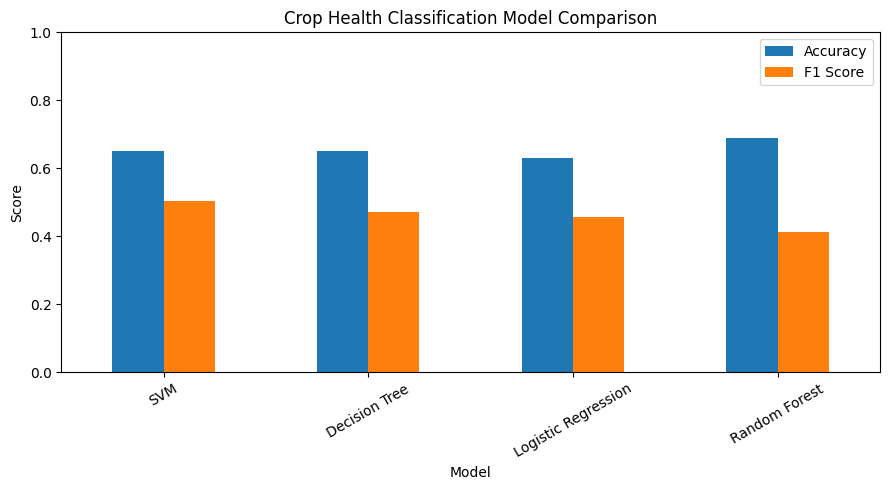

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_pred),
        "Precision": precision_score(
            y_test, lr_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, lr_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, lr_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, dt_pred),
        "Precision": precision_score(
            y_test, dt_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, dt_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, dt_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(
            y_test, rf_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, rf_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, rf_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_test, svm_pred),
        "Precision": precision_score(
            y_test, svm_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, svm_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, svm_pred, average="macro", zero_division=0
        )
    }
])

comparison = comparison.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(comparison)
comparison.set_index("Model")[
    ["Accuracy", "F1 Score"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Crop Health Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
import joblib

# Models already trained in previous cells
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

# Find the best model from the comparison table
best_model_name = comparison.loc[0, "Model"]
best_model = models[best_model_name]

# Save the best model
joblib.dump(best_model, "best_crop_health_model.pkl")

print("Best Model:", best_model_name)
print("Macro F1 Score:", comparison.loc[0, "F1 Score"])
print("Model saved successfully as best_crop_health_model.pkl")

Best Model: SVM
Macro F1 Score: 0.5047180693983019
Model saved successfully as best_crop_health_model.pkl
